# Historical benchmark: 10 and 30 nodes



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
output = ROOT / "results/benchmark/graph_sizes"
output.mkdir(parents=True, exist_ok=True)


## Archived size panels


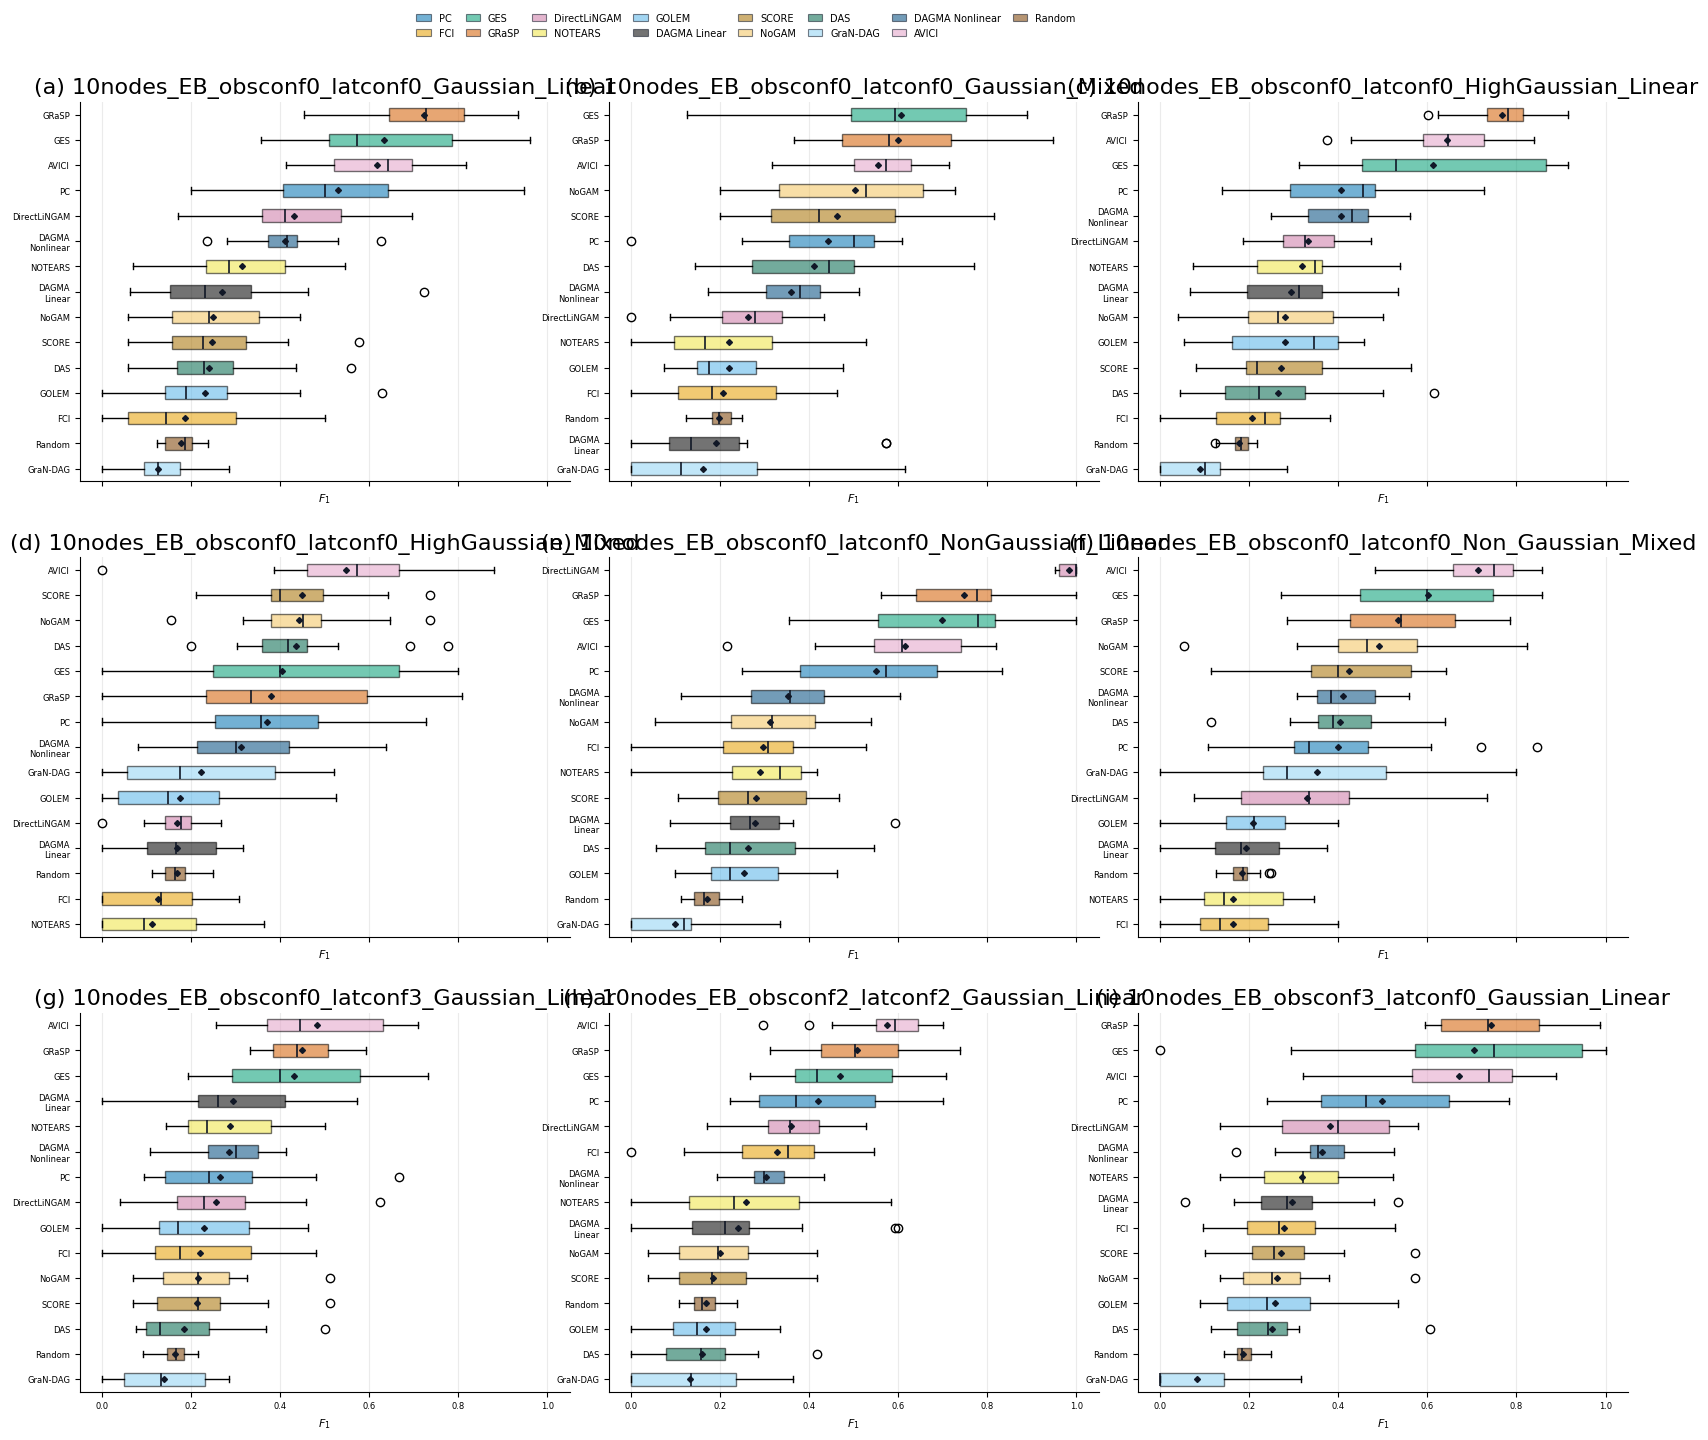

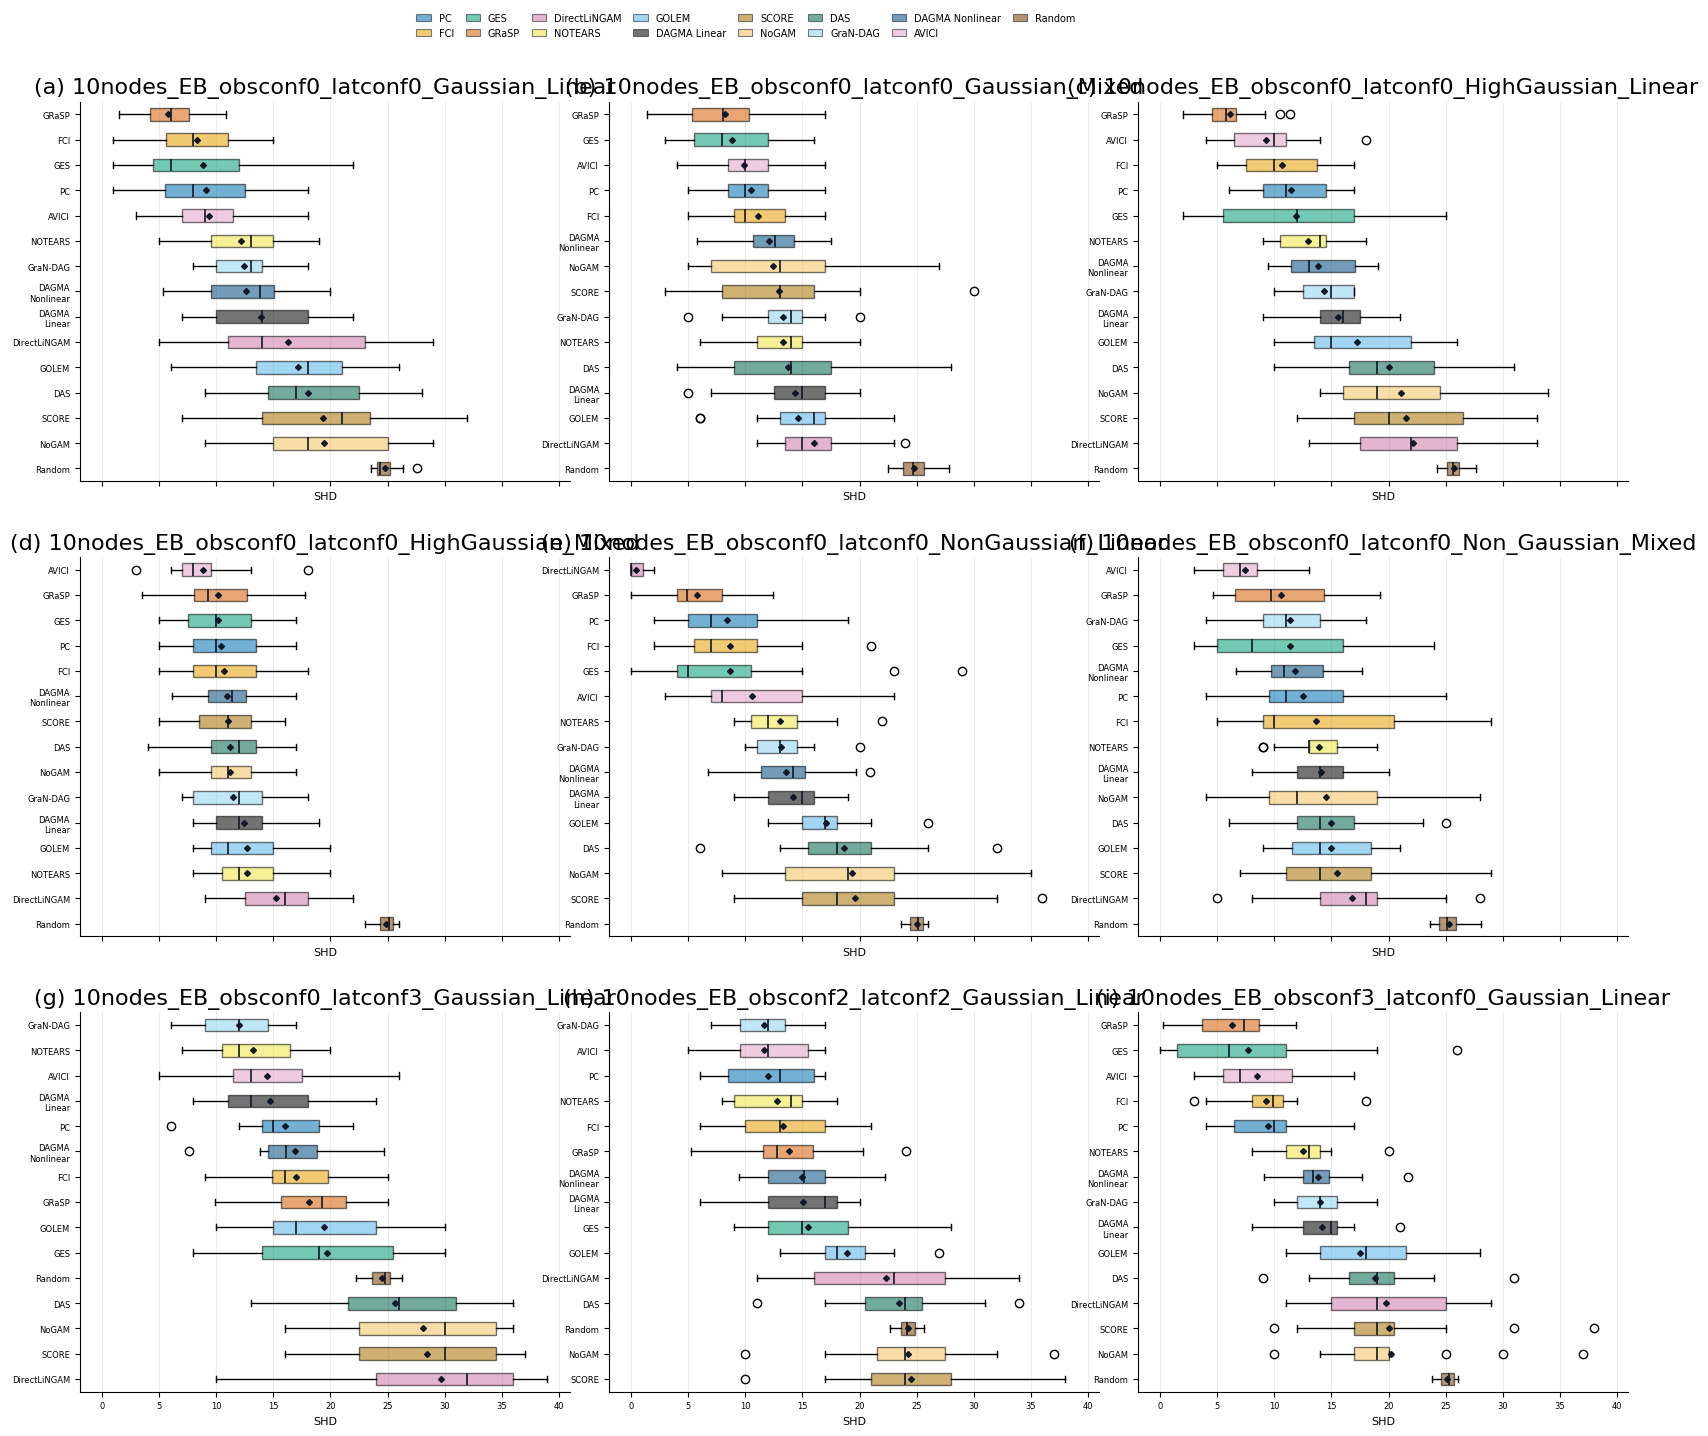

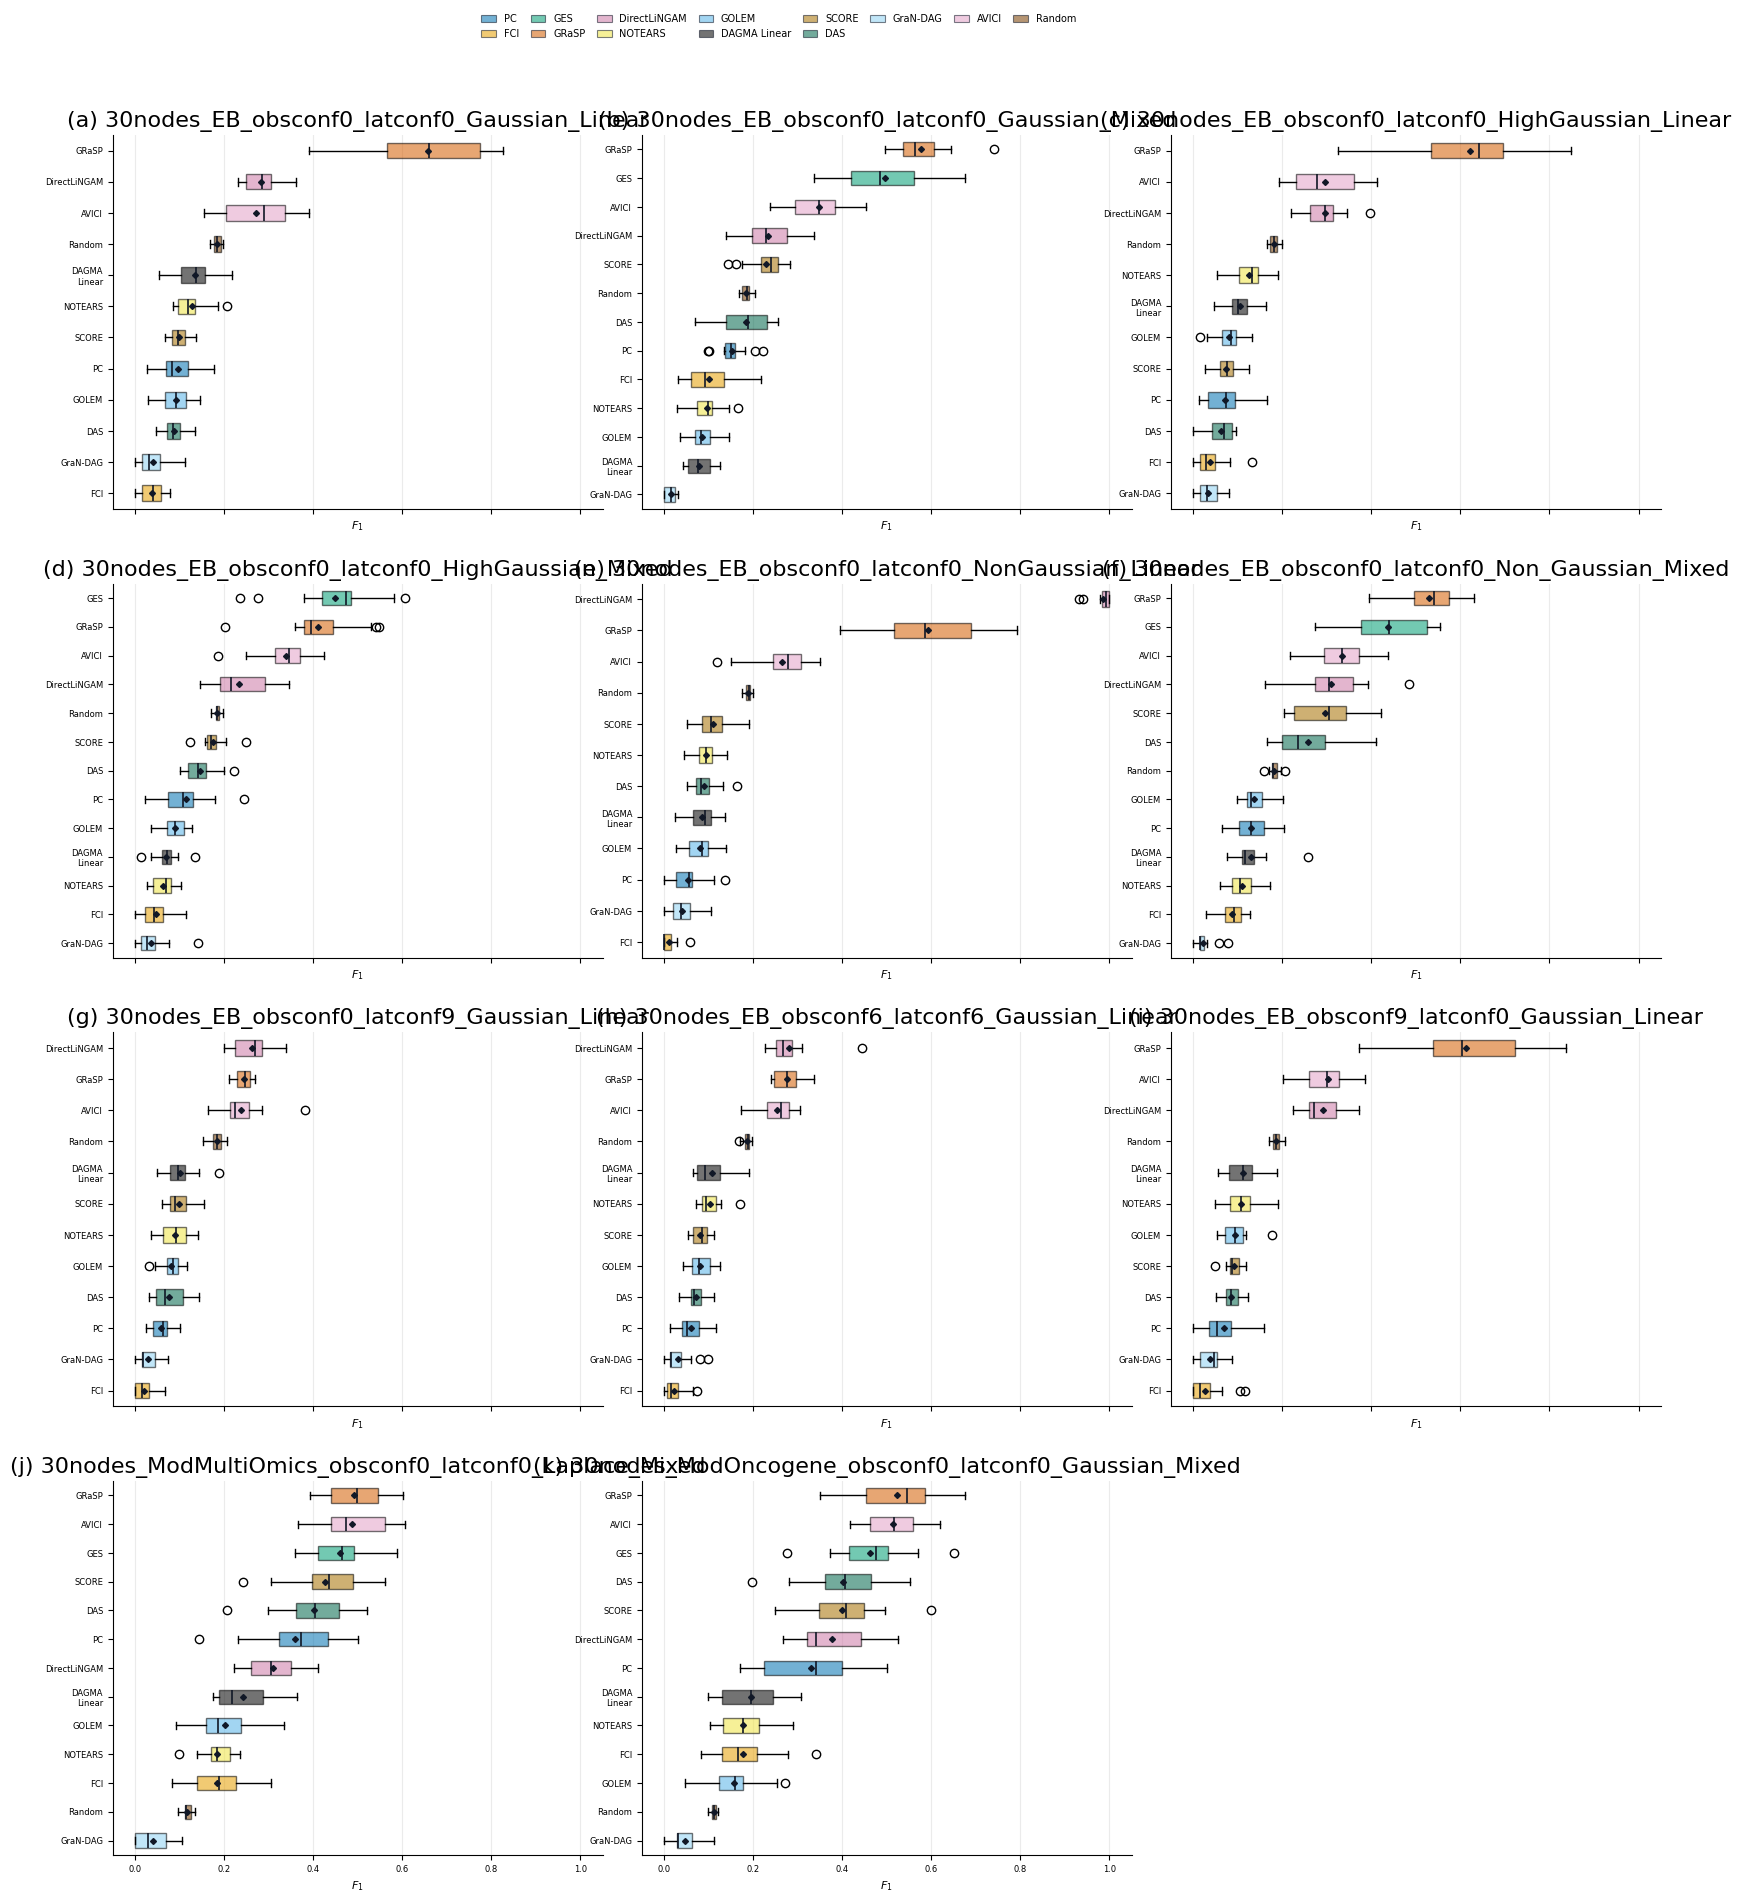

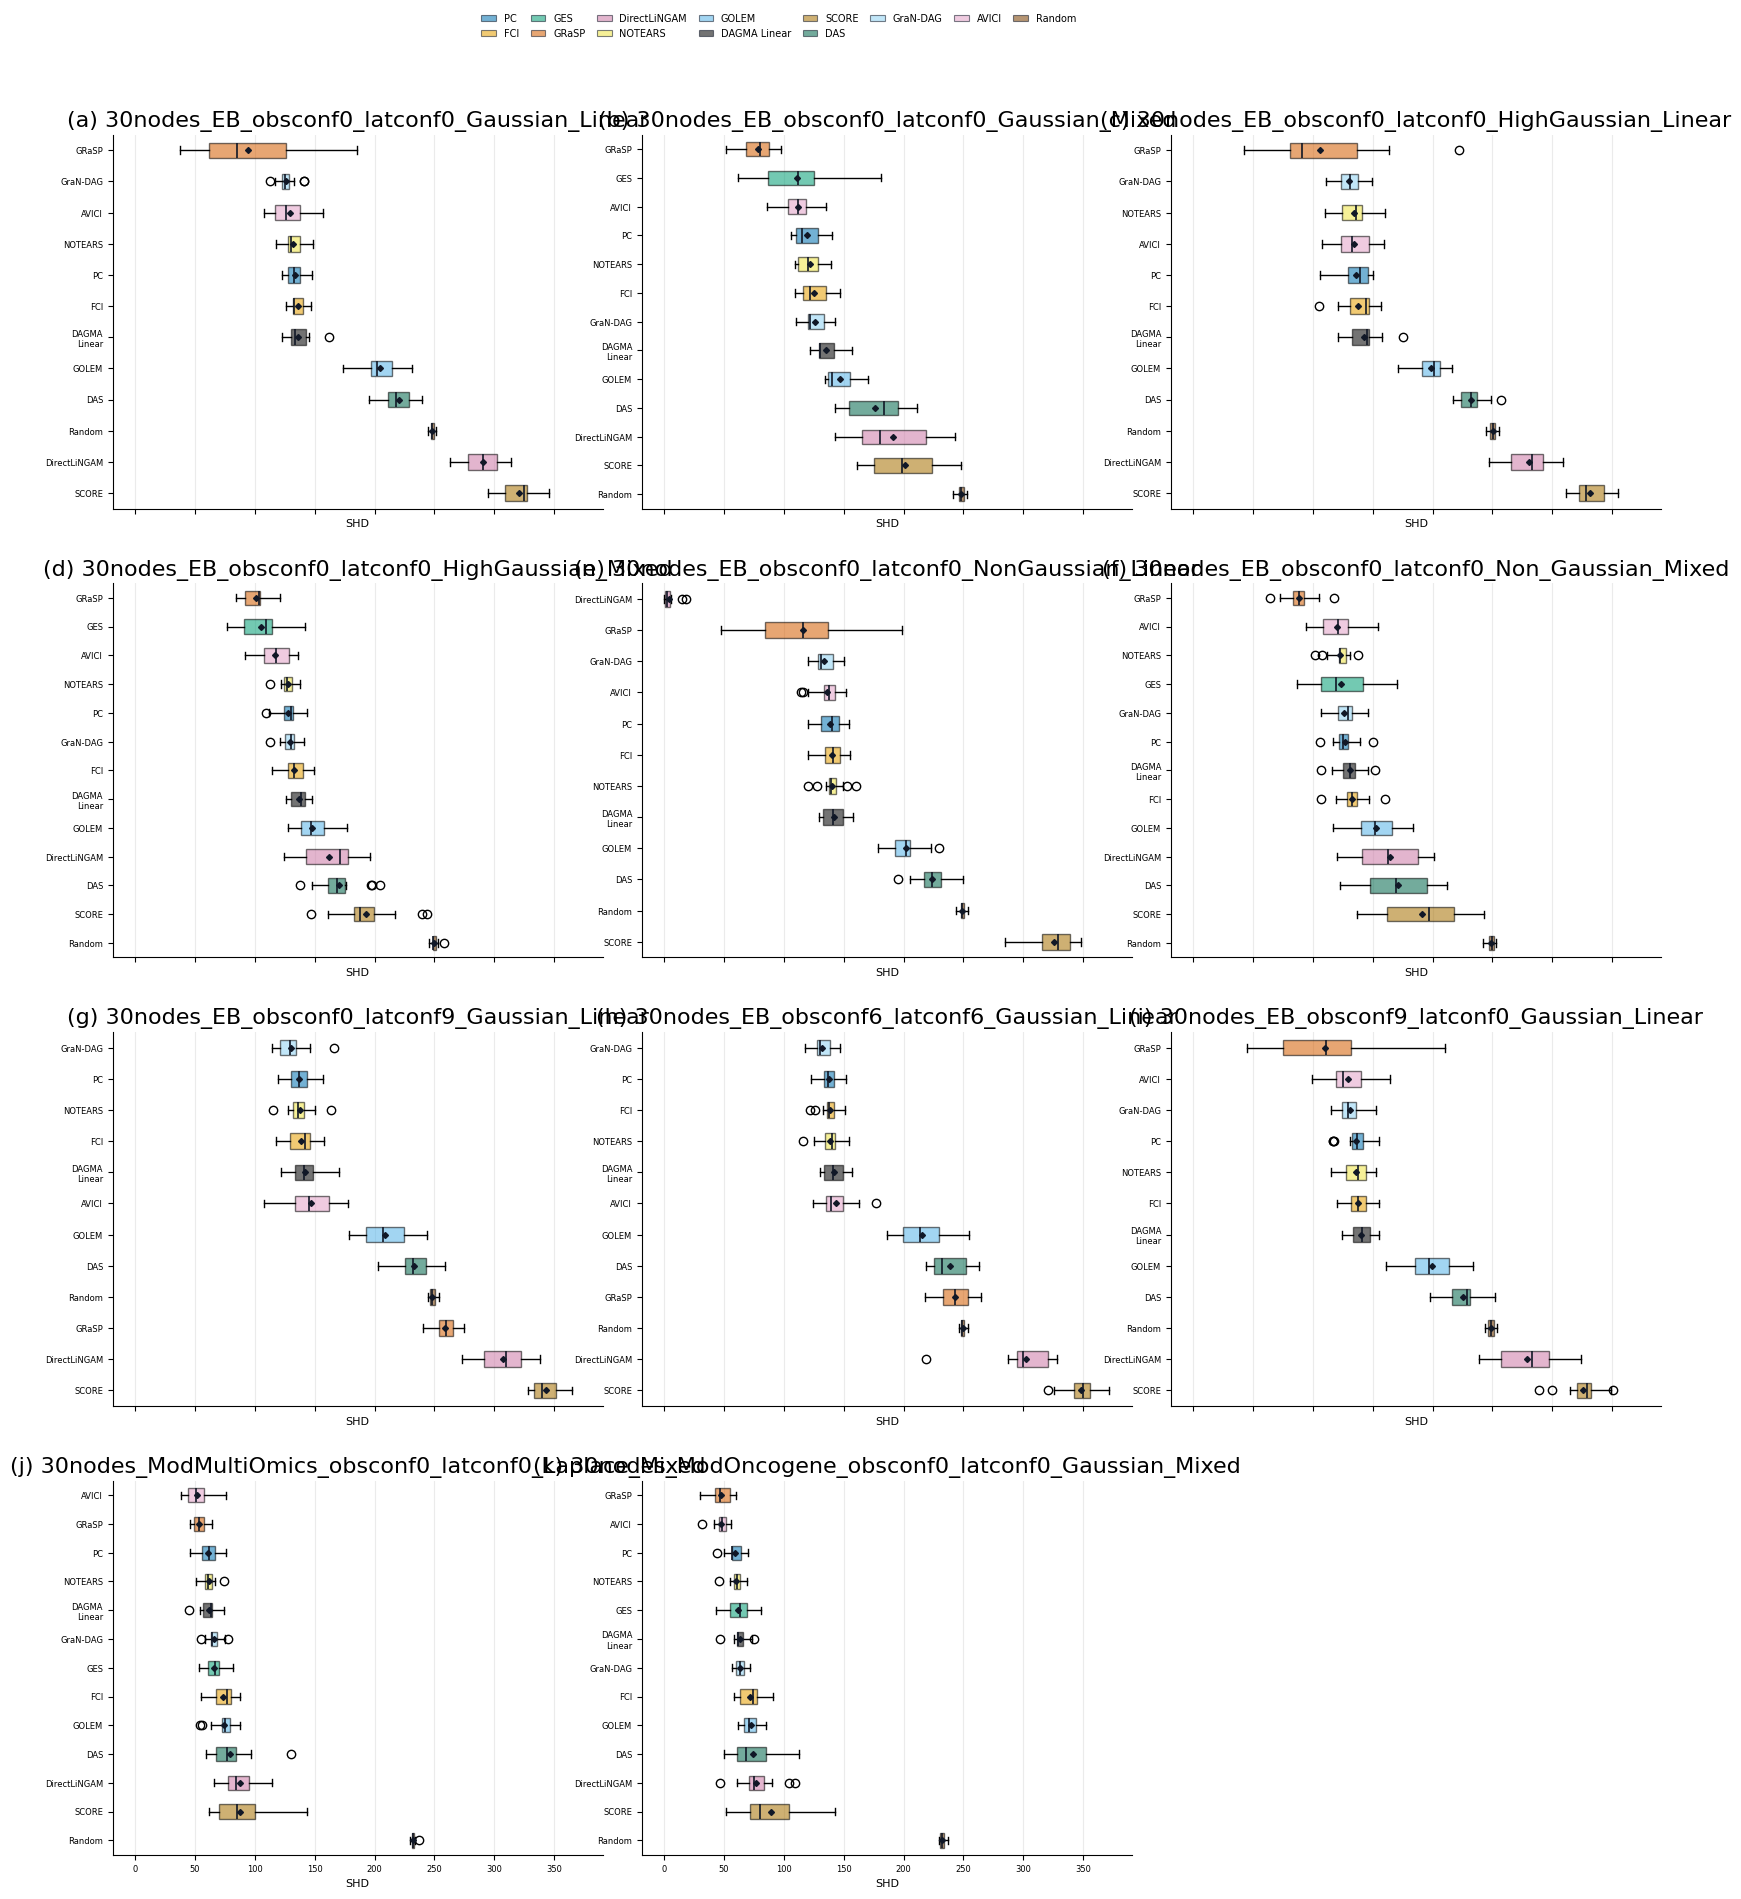

In [2]:
# Summarise each graph size separately.
archived = th.prepare_metrics(th.load_historical_benchmark())
for size in (10, 30):
    frame = archived.loc[archived.n_nodes.eq(size)]
    for metric in ("f1", "SHD"):
        specs = [
            {"title": family, "datasets": family} for family in sorted(frame.dataset.unique())
        ]
        fig, _, _ = fv.plot_metric_boxplot_grid(
            th.visualization_data(frame),
            specs,
            metric=metric,
            coverage_policy="all",
            ncols=3,
            figsize=(18, 5 * ((len(specs) + 2) // 3)),
            font_size=8,
        )
        fig.savefig(output / f"appendix_{size}_nodes_{metric}.pdf", bbox_inches="tight")
        display(fig)
        plt.close(fig)


## Mean and standard deviation by graph size

Model runs are averaged within each dataset instance. The tables report the mean and sample standard deviation across dataset instances, using completed runs. Dashes indicate no completed run. The high-variance Gaussian linear control is omitted from the comparison.


In [3]:
from condition_data import load_results

runs = load_results("benchmark")
runs = runs.loc[runs.status.eq("finished")]
for size in (10, 20, 30):
    selected = runs.loc[runs.n_nodes.eq(size) & ~runs.dataset.str.contains("HighGaussian_Linear")]
    for metric in ("f1", "SHD"):
        blocks = selected.groupby(["dataset", "dataset_seed", "model"])[metric].mean().reset_index()
        summary = blocks.groupby(["dataset", "model"])[metric].agg(["mean", "std", "size"]).reset_index()
        summary["score"] = summary.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)
        table = summary.pivot(index="model", columns="dataset", values="score")
        table = table.reindex([m for m in fv.DEFAULT_MODEL_ORDER if m in runs.model.unique()])
        table.index = [th.model_label(m) for m in table.index]
        table = table.fillna("—").reset_index(names="Method")
        display(table)


dataset,Method,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10nodes_EB_obsconf0_latconf0_Gaussian_Mixed,10nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,10nodes_EB_obsconf0_latconf0_NonGaussian_Linear,10nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,10nodes_EB_obsconf0_latconf3_Gaussian_Linear,10nodes_EB_obsconf2_latconf2_Gaussian_Linear,10nodes_EB_obsconf3_latconf0_Gaussian_Linear
0,PC,0.529 ± 0.204,0.441 ± 0.165,0.370 ± 0.200,0.549 ± 0.180,0.399 ± 0.201,0.265 ± 0.158,0.419 ± 0.166,0.497 ± 0.176
1,FCI,0.187 ± 0.158,0.206 ± 0.157,0.125 ± 0.104,0.297 ± 0.139,0.162 ± 0.125,0.220 ± 0.164,0.328 ± 0.147,0.277 ± 0.130
2,GES,0.634 ± 0.198,0.606 ± 0.200,0.404 ± 0.266,0.698 ± 0.189,0.600 ± 0.196,0.430 ± 0.175,0.468 ± 0.141,0.704 ± 0.297
3,GRaSP,0.723 ± 0.134,0.599 ± 0.177,0.379 ± 0.258,0.746 ± 0.124,0.534 ± 0.155,0.450 ± 0.086,0.506 ± 0.118,0.743 ± 0.128
4,DirectLiNGAM,0.432 ± 0.148,0.263 ± 0.122,0.168 ± 0.067,0.983 ± 0.022,0.330 ± 0.186,0.256 ± 0.152,0.358 ± 0.098,0.380 ± 0.138
5,NOTEARS,0.314 ± 0.131,0.221 ± 0.163,0.112 ± 0.127,0.288 ± 0.120,0.165 ± 0.119,0.288 ± 0.120,0.258 ± 0.172,0.318 ± 0.112
6,GOLEM,0.231 ± 0.156,0.219 ± 0.116,0.175 ± 0.160,0.253 ± 0.117,0.207 ± 0.106,0.229 ± 0.141,0.167 ± 0.097,0.258 ± 0.135
7,DAGMA Linear,0.269 ± 0.170,0.190 ± 0.171,0.168 ± 0.113,0.279 ± 0.118,0.194 ± 0.105,0.293 ± 0.160,0.240 ± 0.170,0.295 ± 0.123
8,SCORE,0.247 ± 0.141,0.461 ± 0.185,0.449 ± 0.137,0.281 ± 0.125,0.424 ± 0.147,0.212 ± 0.121,0.184 ± 0.109,0.272 ± 0.118
9,NoGAM,0.248 ± 0.121,0.502 ± 0.178,0.443 ± 0.140,0.312 ± 0.134,0.491 ± 0.195,0.216 ± 0.115,0.200 ± 0.109,0.262 ± 0.115


dataset,Method,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10nodes_EB_obsconf0_latconf0_Gaussian_Mixed,10nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,10nodes_EB_obsconf0_latconf0_NonGaussian_Linear,10nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,10nodes_EB_obsconf0_latconf3_Gaussian_Linear,10nodes_EB_obsconf2_latconf2_Gaussian_Linear,10nodes_EB_obsconf3_latconf0_Gaussian_Linear
0,PC,9.067 ± 4.920,10.467 ± 2.875,10.400 ± 3.501,8.400 ± 4.532,12.533 ± 5.780,16.000 ± 4.053,12.000 ± 4.175,9.400 ± 3.460
1,FCI,8.338 ± 3.998,11.067 ± 3.494,10.667 ± 3.867,8.667 ± 4.995,13.684 ± 7.294,16.991 ± 3.904,13.267 ± 4.773,9.293 ± 3.483
2,GES,8.867 ± 6.653,8.800 ± 3.950,10.133 ± 3.623,8.667 ± 8.006,11.400 ± 7.670,19.667 ± 7.218,15.467 ± 5.055,7.667 ± 8.042
3,GRaSP,5.760 ± 2.543,8.253 ± 4.182,10.124 ± 3.732,5.809 ± 3.113,10.609 ± 4.756,18.124 ± 4.834,13.809 ± 4.581,6.320 ± 3.275
4,DirectLiNGAM,16.267 ± 7.245,16.000 ± 3.873,15.267 ± 3.936,0.467 ± 0.640,16.800 ± 6.062,29.667 ± 8.139,22.333 ± 7.078,19.733 ± 6.135
5,NOTEARS,12.200 ± 3.821,13.333 ± 4.169,12.733 ± 3.390,13.000 ± 3.586,13.933 ± 3.283,13.200 ± 3.986,12.733 ± 3.127,12.467 ± 3.021
6,GOLEM,17.133 ± 5.998,14.600 ± 4.517,12.667 ± 3.848,17.067 ± 3.494,15.000 ± 3.836,19.400 ± 6.423,18.933 ± 3.327,17.533 ± 5.055
7,DAGMA Linear,13.933 ± 5.049,14.333 ± 4.530,12.467 ± 3.226,14.133 ± 2.949,14.067 ± 3.390,14.667 ± 4.746,15.067 ± 4.250,14.200 ± 3.121
8,SCORE,19.333 ± 7.594,12.933 ± 6.902,11.000 ± 3.024,19.600 ± 7.414,15.467 ± 6.589,28.467 ± 7.249,24.533 ± 6.875,20.067 ± 7.045
9,NoGAM,19.467 ± 6.707,12.467 ± 6.368,11.200 ± 3.121,19.333 ± 7.423,14.533 ± 7.239,28.067 ± 6.819,24.267 ± 6.617,20.200 ± 6.450


dataset,Method,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
0,PC,0.168 ± 0.089,0.238 ± 0.092,0.219 ± 0.099,0.142 ± 0.068,0.229 ± 0.073,0.115 ± 0.059,0.146 ± 0.054,0.168 ± 0.076,0.378 ± 0.095,0.373 ± 0.098
1,FCI,0.089 ± 0.063,0.154 ± 0.071,0.131 ± 0.065,0.079 ± 0.064,0.165 ± 0.066,0.052 ± 0.043,0.063 ± 0.054,0.089 ± 0.064,0.167 ± 0.096,0.219 ± 0.117
2,GES,0.394 ± 0.179,0.573 ± 0.093,0.532 ± 0.091,0.444 ± 0.152,0.537 ± 0.149,0.329 ± 0.119,0.304 ± 0.084,0.423 ± 0.201,0.434 ± 0.143,0.485 ± 0.091
3,GRaSP,0.794 ± 0.098,0.586 ± 0.091,0.471 ± 0.085,0.756 ± 0.114,0.605 ± 0.095,0.296 ± 0.042,0.388 ± 0.073,0.781 ± 0.078,0.437 ± 0.110,0.472 ± 0.096
4,DirectLiNGAM,0.333 ± 0.089,0.208 ± 0.114,0.199 ± 0.085,0.998 ± 0.003,0.375 ± 0.092,0.282 ± 0.072,0.269 ± 0.067,0.316 ± 0.079,0.307 ± 0.084,0.352 ± 0.064
5,NOTEARS,0.194 ± 0.071,0.141 ± 0.072,0.125 ± 0.062,0.180 ± 0.056,0.150 ± 0.072,0.132 ± 0.037,0.146 ± 0.041,0.175 ± 0.081,0.245 ± 0.093,0.238 ± 0.104
6,GOLEM,0.125 ± 0.048,0.136 ± 0.070,0.103 ± 0.067,0.150 ± 0.091,0.150 ± 0.063,0.109 ± 0.043,0.134 ± 0.066,0.124 ± 0.055,0.318 ± 0.150,0.231 ± 0.083
7,DAGMA Linear,0.190 ± 0.089,0.138 ± 0.077,0.107 ± 0.078,0.180 ± 0.063,0.162 ± 0.063,0.139 ± 0.053,0.169 ± 0.049,0.183 ± 0.107,0.298 ± 0.125,0.244 ± 0.097
8,SCORE,0.119 ± 0.060,0.311 ± 0.083,0.232 ± 0.085,0.141 ± 0.080,0.339 ± 0.056,0.103 ± 0.047,0.112 ± 0.046,0.124 ± 0.055,0.464 ± 0.086,0.414 ± 0.068
9,NoGAM,0.120 ± 0.060,0.343 ± 0.095,0.262 ± 0.099,0.139 ± 0.080,0.383 ± 0.089,0.103 ± 0.041,0.113 ± 0.040,0.114 ± 0.049,0.491 ± 0.095,0.438 ± 0.058


dataset,Method,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
0,PC,57.667 ± 9.431,50.600 ± 9.583,52.133 ± 8.391,60.600 ± 7.385,51.933 ± 9.020,64.400 ± 7.808,62.467 ± 7.140,58.000 ± 8.799,28.267 ± 4.383,27.733 ± 5.120
1,FCI,59.876 ± 9.870,51.973 ± 10.093,53.858 ± 9.207,62.591 ± 7.203,54.262 ± 10.045,65.658 ± 8.710,66.302 ± 7.654,60.667 ± 8.608,31.467 ± 6.501,32.960 ± 6.478
2,GES,89.400 ± 34.442,40.200 ± 11.742,41.667 ± 10.998,80.267 ± 27.112,46.600 ± 17.087,116.867 ± 21.074,122.133 ± 15.052,83.000 ± 36.625,30.067 ± 6.923,27.933 ± 5.496
3,GRaSP,23.169 ± 14.850,34.809 ± 8.720,42.182 ± 7.921,28.404 ± 15.398,35.702 ± 9.969,105.942 ± 10.990,86.738 ± 13.556,24.200 ± 11.001,26.511 ± 5.200,24.187 ± 4.325
4,DirectLiNGAM,105.600 ± 17.357,82.600 ± 23.200,77.933 ± 20.927,0.200 ± 0.414,68.333 ± 18.734,133.867 ± 16.022,135.000 ± 12.107,112.200 ± 21.475,37.600 ± 6.822,36.000 ± 10.556
5,NOTEARS,56.133 ± 8.417,53.600 ± 7.327,54.333 ± 7.188,59.467 ± 6.988,54.600 ± 8.227,63.000 ± 4.971,61.800 ± 6.549,58.000 ± 8.255,25.600 ± 3.719,24.600 ± 4.339
6,GOLEM,85.533 ± 11.831,62.667 ± 8.600,63.133 ± 10.099,84.400 ± 13.474,68.000 ± 11.850,96.467 ± 12.438,92.733 ± 8.648,86.467 ± 12.212,29.600 ± 7.642,29.933 ± 5.311
7,DAGMA Linear,60.267 ± 8.996,57.667 ± 8.474,58.933 ± 8.163,61.533 ± 7.558,59.400 ± 8.450,68.533 ± 4.764,66.000 ± 5.043,61.067 ± 10.032,25.400 ± 4.968,25.467 ± 4.357
8,SCORE,130.133 ± 16.448,74.867 ± 14.672,76.733 ± 15.926,133.800 ± 17.292,80.667 ± 11.824,151.333 ± 10.479,148.667 ± 8.583,129.067 ± 20.094,34.933 ± 7.005,38.867 ± 7.434
9,NoGAM,129.933 ± 15.411,72.733 ± 15.369,74.400 ± 14.131,134.000 ± 17.142,76.133 ± 14.952,151.133 ± 9.899,148.267 ± 9.339,130.133 ± 17.541,34.000 ± 8.896,37.533 ± 6.632


dataset,Method,30nodes_EB_obsconf0_latconf0_Gaussian_Linear,30nodes_EB_obsconf0_latconf0_Gaussian_Mixed,30nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,30nodes_EB_obsconf0_latconf0_NonGaussian_Linear,30nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,30nodes_EB_obsconf0_latconf9_Gaussian_Linear,30nodes_EB_obsconf6_latconf6_Gaussian_Linear,30nodes_EB_obsconf9_latconf0_Gaussian_Linear,30nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,30nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
0,PC,0.097 ± 0.041,0.151 ± 0.033,0.114 ± 0.055,0.053 ± 0.038,0.130 ± 0.037,0.059 ± 0.021,0.060 ± 0.030,0.069 ± 0.047,0.360 ± 0.097,0.330 ± 0.109
1,FCI,0.038 ± 0.026,0.101 ± 0.053,0.047 ± 0.034,0.011 ± 0.017,0.087 ± 0.029,0.019 ± 0.019,0.023 ± 0.025,0.027 ± 0.039,0.184 ± 0.066,0.176 ± 0.072
2,GES,—,0.496 ± 0.108,0.450 ± 0.098,—,0.437 ± 0.092,—,—,—,0.460 ± 0.064,0.463 ± 0.090
3,GRaSP,0.657 ± 0.132,0.578 ± 0.062,0.411 ± 0.086,0.592 ± 0.111,0.529 ± 0.072,0.244 ± 0.018,0.275 ± 0.031,0.613 ± 0.130,0.492 ± 0.068,0.523 ± 0.100
4,DirectLiNGAM,0.283 ± 0.039,0.232 ± 0.054,0.234 ± 0.064,0.985 ± 0.021,0.309 ± 0.079,0.263 ± 0.044,0.281 ± 0.051,0.292 ± 0.047,0.311 ± 0.062,0.377 ± 0.081
5,NOTEARS,0.127 ± 0.038,0.096 ± 0.036,0.062 ± 0.025,0.094 ± 0.031,0.109 ± 0.032,0.090 ± 0.033,0.103 ± 0.025,0.107 ± 0.037,0.184 ± 0.038,0.177 ± 0.054
6,GOLEM,0.092 ± 0.034,0.084 ± 0.031,0.089 ± 0.026,0.081 ± 0.033,0.137 ± 0.030,0.082 ± 0.023,0.080 ± 0.025,0.094 ± 0.032,0.203 ± 0.068,0.156 ± 0.060
7,DAGMA Linear,0.134 ± 0.041,0.079 ± 0.028,0.070 ± 0.028,0.085 ± 0.030,0.129 ± 0.043,0.101 ± 0.036,0.106 ± 0.042,0.112 ± 0.040,0.243 ± 0.062,0.195 ± 0.068
8,SCORE,0.099 ± 0.021,0.229 ± 0.041,0.175 ± 0.028,0.110 ± 0.037,0.296 ± 0.075,0.099 ± 0.029,0.081 ± 0.018,0.091 ± 0.019,0.427 ± 0.086,0.400 ± 0.089
9,NoGAM,—,—,—,—,—,—,—,—,—,—


dataset,Method,30nodes_EB_obsconf0_latconf0_Gaussian_Linear,30nodes_EB_obsconf0_latconf0_Gaussian_Mixed,30nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,30nodes_EB_obsconf0_latconf0_NonGaussian_Linear,30nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,30nodes_EB_obsconf0_latconf9_Gaussian_Linear,30nodes_EB_obsconf6_latconf6_Gaussian_Linear,30nodes_EB_obsconf9_latconf0_Gaussian_Linear,30nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,30nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed
0,PC,133.200 ± 7.370,119.733 ± 10.918,127.800 ± 9.843,138.267 ± 10.152,126.467 ± 9.833,137.267 ± 10.938,137.400 ± 7.818,136.333 ± 11.812,61.067 ± 8.713,59.267 ± 6.964
1,FCI,135.800 ± 6.700,125.036 ± 12.018,132.653 ± 10.401,139.867 ± 10.042,132.529 ± 12.040,138.600 ± 11.885,138.267 ± 7.620,137.933 ± 10.727,73.476 ± 9.726,71.871 ± 9.493
2,GES,—,110.667 ± 34.780,105.067 ± 17.153,—,123.500 ± 25.570,—,—,—,65.933 ± 8.216,61.867 ± 10.141
3,GRaSP,94.307 ± 41.587,78.427 ± 13.386,100.627 ± 10.654,115.920 ± 38.996,88.218 ± 12.817,258.742 ± 9.678,242.929 ± 14.873,110.364 ± 45.909,53.547 ± 6.108,47.467 ± 8.849
4,DirectLiNGAM,290.600 ± 15.838,191.000 ± 34.239,162.400 ± 22.915,3.800 ± 5.532,164.267 ± 27.259,307.533 ± 19.052,301.933 ± 27.204,279.200 ± 27.355,87.267 ± 13.931,77.067 ± 15.632
5,NOTEARS,131.933 ± 9.924,121.667 ± 10.574,127.533 ± 6.174,140.333 ± 9.507,122.600 ± 9.233,137.667 ± 11.331,138.533 ± 9.635,136.400 ± 10.742,61.600 ± 5.409,59.800 ± 5.226
6,GOLEM,204.867 ± 14.851,146.667 ± 12.122,147.867 ± 14.071,201.800 ± 13.914,152.400 ± 17.602,208.600 ± 19.283,215.800 ± 20.675,199.800 ± 21.227,74.600 ± 10.218,72.333 ± 7.178
7,DAGMA Linear,135.867 ± 10.246,134.867 ± 9.716,136.800 ± 7.821,141.733 ± 9.177,130.667 ± 11.727,141.667 ± 11.412,142.067 ± 9.239,140.000 ± 9.695,61.667 ± 7.537,63.067 ± 6.724
8,SCORE,320.333 ± 14.749,200.800 ± 29.280,192.933 ± 25.594,325.400 ± 18.623,190.933 ± 35.574,342.867 ± 10.822,348.267 ± 13.588,325.600 ± 16.075,87.600 ± 22.513,89.133 ± 24.588
9,NoGAM,—,—,—,—,—,—,—,—,—,—
